## Практическое задание №5
#### по дисциплине "Введение в анализ данных"

*Работу выполнил*: Евсеев Григорий, 3826Б1ПМад1

### Часть 1.

Импорт библиотек

In [1]:
import xlrd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

Вспомогательная функция для импорта из файла:

In [2]:
def importData(bookName, sheetInd):
    res = []
    book = xlrd.open_workbook(bookName)
    sheet = book.sheet_by_index(sheetInd)
    for i in range(1, sheet.nrows):
        res.append(sheet.row_values(i, 0, sheet.ncols))
    return res

examsData = importData('04_Экзамены.xlsx', 0)

In [3]:
types = {0: "Пол", 1: "Расовая группа", 2: "Образование родителей",
         3: "Наличие льгот", 4: "Подготовительный курс",
         5: "Оценка по математике", 6: "Оценка по чтению", 7: "Оценка по письму"}

genderTypes = {"male": "М", "female": "Ж"}
raceTypes = {"group A": 0, "group B": 1, "group C": 2, "group D": 3, "group E": 4}
edTypes = {"some high school": 0, "high school": 1, "some college": 2,
           "associate's degree": 3, "bachelor's degree": 4, "master's degree": 5}
lunchTypes = {"standard": "нет", "free/reduced": "да"}
prepTypes = {"none": "нет", "completed": "да"}

for sample in examsData:
    sample[0] = genderTypes[sample[0]]
    sample[1] = raceTypes[sample[1]]
    sample[2] = edTypes[sample[2]]
    sample[3] = lunchTypes[sample[3]]
    sample[4] = prepTypes[sample[4]]

def dataByType(data, type):
    res = []
    for rec in data:
        res.append(rec[type])
    return res

numData = [5, 6, 7]

Простая линейная регрессия

In [4]:
# разделение выборки на тренировочную и проверочную
examsTr, examsVal = train_test_split(examsData, test_size = 0.2, train_size = 0.8)

# независимая переменная - оценка по математике, зависимая - по письму
X = np.reshape(dataByType(examsTr, 5), (-1, 1))

# обучение модели
linR = LinearRegression().fit(X, dataByType(examsTr, 7))

a = linR.coef_
b = linR.intercept_
print("Построенная зависимость: Y = " + str(a[0]) + "*x + " + str(b))

# валидация модели на проверочной выборке
Y_predict = linR.predict(np.reshape(dataByType(examsVal, 5), (-1, 1)))

# коэффициент R^2 (2 варианта подсчета)
r2_1 = r2_score(dataByType(examsVal, 7), Y_predict)
# linR.score(np.reshape(dataByType(examsVal, 6), (-1, 1)), dataByType(examsVal, 7))
print("Коэффициент детерминации = " + str(r2_1))

# средняя квадратическая ошибка
mse_1 = mean_squared_error(dataByType(examsVal, 7), Y_predict)
print("Средняя квадратическая ошибка MSE = " + str(mse_1))

# Остаточная сумма квадратов
rss_1 = ((dataByType(examsVal, 7) - Y_predict)**2).sum()
print("Остаточная сумма квадратов RSS = " + str(rss_1))

Построенная зависимость: Y = 0.8036604848831607*x + 14.891411314382836
Коэффициент детерминации = 0.6295810629998311
Средняя квадратическая ошибка MSE = 78.71387594496109
Остаточная сумма квадратов RSS = 15742.775188992216


In [5]:
dataByType(examsTr, 5)[0:10]

[79.0, 40.0, 80.0, 73.0, 52.0, 59.0, 64.0, 71.0, 58.0, 48.0]

In [6]:
np.reshape(dataByType(examsTr, 5), (-1, 1))[0:10]

array([[79.],
       [40.],
       [80.],
       [73.],
       [52.],
       [59.],
       [64.],
       [71.],
       [58.],
       [48.]])

Визуализация данных:

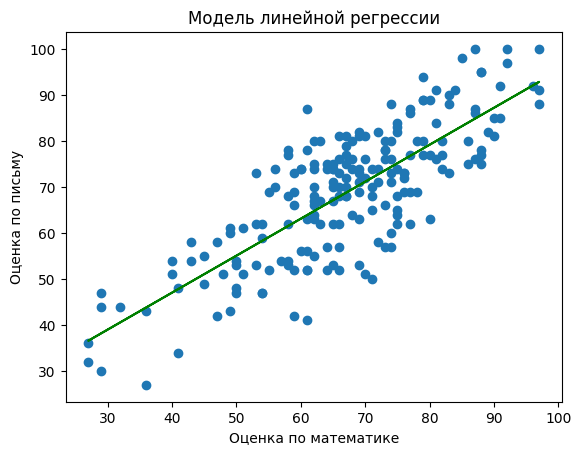

In [7]:
plt.scatter(dataByType(examsVal, 5), dataByType(examsVal, 7))
plt.plot(dataByType(examsVal, 5), Y_predict, color = 'green')
plt.title("Модель линейной регрессии")
plt.xlabel("Оценка по математике")
plt.ylabel("Оценка по письму")
plt.show()

In [8]:
houseData = importData('06_СтоимостьДомов.xlsx', 0)
houseData

[['7129300520',
  20141013.0,
  '221900',
  '3',
  '1',
  '1180',
  '5650',
  '1',
  '0',
  '0',
  '3',
  '7',
  '1180',
  '0',
  '1955',
  '0',
  '1340',
  '5650'],
 ['6414100192',
  20141209.0,
  '538000',
  '3',
  '2.25',
  '2570',
  '7242',
  '2',
  '0',
  '0',
  '3',
  '7',
  '2170',
  '400',
  '1951',
  '1991',
  '1690',
  '7639'],
 ['5631500400',
  20150225.0,
  '180000',
  '2',
  '1',
  '770',
  '10000',
  '1',
  '0',
  '0',
  '3',
  '6',
  '770',
  '0',
  '1933',
  '0',
  '2720',
  '8062'],
 ['2487200875',
  20141209.0,
  '604000',
  '4',
  '3',
  '1960',
  '5000',
  '1',
  '0',
  '0',
  '5',
  '7',
  '1050',
  '910',
  '1965',
  '0',
  '1360',
  '5000'],
 ['1954400510',
  20150218.0,
  '510000',
  '3',
  '2',
  '1680',
  '8080',
  '1',
  '0',
  '0',
  '3',
  '8',
  '1680',
  '0',
  '1987',
  '0',
  '1800',
  '7503'],
 ['7237550310',
  20140512.0,
  '1.225e+006',
  '4',
  '4.5',
  '5420',
  '101930',
  '1',
  '0',
  '0',
  '3',
  '11',
  '3890',
  '1530',
  '2001',
  '0',
  '4

In [9]:
def polynomicSample(data, degree):
    res = []
    for rec in data:
        for every in rec:
            x = float(every)
            for d in range(degree):
                res.append(x**(d + 1))
    res = np.reshape(res, (len(data), -1))
    return res

In [10]:
print("Исходные значения оценки дома (столбец 11):")
print(np.reshape(dataByType(houseData, 11), (-1, 1))[0:5])

print("\nПолиномиальные признаки 3-й степени для оценки дома:")
print(polynomicSample(np.reshape(dataByType(houseData, 11), (-1, 1)), 3)[0:5])

Исходные значения оценки дома (столбец 11):
[['7']
 ['7']
 ['6']
 ['7']
 ['8']]

Полиномиальные признаки 3-й степени для оценки дома:
[[  7.  49. 343.]
 [  7.  49. 343.]
 [  6.  36. 216.]
 [  7.  49. 343.]
 [  8.  64. 512.]]


In [11]:
def numList(data, col):
    return np.array([float(v) for v in dataByType(data, col)])


In [12]:
houseDataTr, houseDataVal = train_test_split(
    houseData, test_size=0.2, train_size=0.8
)

r2, er, rss = [], [], []

X_tr  = numList(houseDataTr, 11).reshape(-1, 1)
X_val = numList(houseDataVal, 11).reshape(-1, 1)
y_tr  = numList(houseDataTr, 2)
y_val = numList(houseDataVal, 2)

linR = LinearRegression().fit(X_tr, y_tr)
Y_predict = linR.predict(X_val)

r2.append(r2_score(y_val, Y_predict))
er.append(mean_squared_error(y_val, Y_predict))
rss.append(((y_val - Y_predict) ** 2).sum())

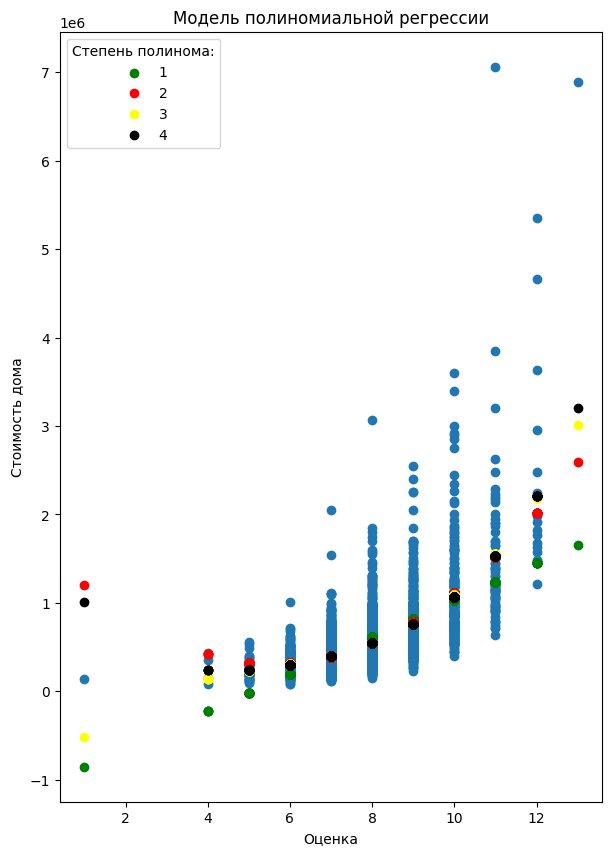

  Степень полинома           R2                MSE                RSS
                 1     0.401669 85004827713.677597 367475870206228.250000
                 2     0.462729 76330039226.607208 329974759576622.937500
                 3     0.473407 74813038062.012466 323416763542079.875000


In [13]:
plts = []
plt.figure(figsize=(7, 10))

# Синие точки — валидационная выборка
plt.scatter(numList(houseDataVal, 11), numList(houseDataVal, 2))

# Зелёные точки — предсказание степени 1 (уже посчитано)
plts.append(plt.scatter(numList(houseDataVal, 11), Y_predict,
                        color='green', label="1"))

plt.title("Модель полиномиальной регрессии")
plt.xlabel("Оценка")
plt.ylabel("Стоимость дома")

colors = ["red", "yellow", "black"]
for d in [2, 3, 4]:
    # Обучение на тренировочной выборке
    squareTr = polynomicSample(numList(houseDataTr, 11).reshape(-1, 1), d)
    linR = LinearRegression().fit(squareTr, numList(houseDataTr, 2))

    # Предсказание — на ВАЛИДАЦИОННОЙ выборке
    squareVal = polynomicSample(numList(houseDataVal, 11).reshape(-1, 1), d)
    Y_predict = linR.predict(squareVal)

    r2.append(r2_score(numList(houseDataVal, 2), Y_predict))
    er.append(mean_squared_error(numList(houseDataVal, 2), Y_predict))
    rss.append(((numList(houseDataVal, 2) - Y_predict) ** 2).sum())

    plts.append(plt.scatter(numList(houseDataVal, 11), Y_predict,
                            color=colors[d - 2], label=str(d)))

plt.legend(title="Степень полинома:", handles=plts, labels=["1", "2", "3", "4"])
plt.show()

print("%18s %12s %18s %18s" % ("Степень полинома", "R2", "MSE", "RSS"))
models = [1, 2, 3, 4]
for i in range(len(r2) - 1):
    print("%18d %12f %18f %18f" % (models[i], r2[i], er[i], rss[i]))

### Часть 2.

#### Пункт 1. Определение типа данных

Подключение библиотек:

In [14]:
import xlrd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

Загрузка данных о зачислении через вспомогательную функцию importData:

In [15]:
def importData(bookName, sheetInd):
    res = []
    book = xlrd.open_workbook(bookName)
    sheet = book.sheet_by_index(sheetInd)
    for i in range(1, sheet.nrows):
        res.append(sheet.row_values(i, 0, sheet.ncols))
    return res

# загрузка данных о зачислении
admissionData = importData('05_Зачисление.xlsx', 0)

Вспомогательные функции:

In [16]:
# функция для извлечения значений из столбца
def dataByType(data, type):
    res = []
    for rec in data:
        res.append(rec[type])
    return res

# функция, получающая числовой массив из столбца
def numList(data, col):
    return np.array([float(v) for v in dataByType(data, col)])

In [17]:
types = {
    0: "Serial No.",
    1: "GRE Score",
    2: "TOEFL Score",
    3: "University Rating",
    4: "SOP",
    5: "LOR",
    6: "CGPA",
    7: "Research",
    8: "Chance of Admit"
}

print("Типы данных по столбцам:")
for i in range(len(types)):
    print(f"  Столбец {i}: {types[i]}")

Типы данных по столбцам:
  Столбец 0: Serial No.
  Столбец 1: GRE Score
  Столбец 2: TOEFL Score
  Столбец 3: University Rating
  Столбец 4: SOP
  Столбец 5: LOR
  Столбец 6: CGPA
  Столбец 7: Research
  Столбец 8: Chance of Admit


Приведены следующие данные:
- `Serial Number` - идентификатор, серийный номер, `int`, качественный номинальный признак;
- `GRE Score` - Graduate record examinations score, оценка на стандартизированный тест, `int`, количественный дискретный;
- `TOEFL Score` - Test of English as a foreign language score, балл за международный тест по английскому языку как иностранному, `int`, количественный дискретный;
- `University Rating` - рейтинг университета, `int`, качественный порядковый признак;
- `SOP` - Statement of purpose, оценка за мотивационное письмо/эссе, `float`, качественный порядковый;
- `LOR` - Letter of recomendation, оценка за письмо-рекомендацию от научного руководителя, преподавателя или работодателя, `float`, качественный порядковый;
- `CGPA` - Cumulative grade point average, пересчитанный в стандартизированную шкалу средний балл диплома бакалавра, `float`, количественный непрерывный;
- `Research` - наличие опубликованных научных работ или статей, `1` если есть, иначе `0`, качественный бинарный;
- `Chance of Admit` - целевая переменная, вероятность поступления, `float`, количественный непрерывный признак.

#### Пункт 2. Построение диаграмм рассеивания

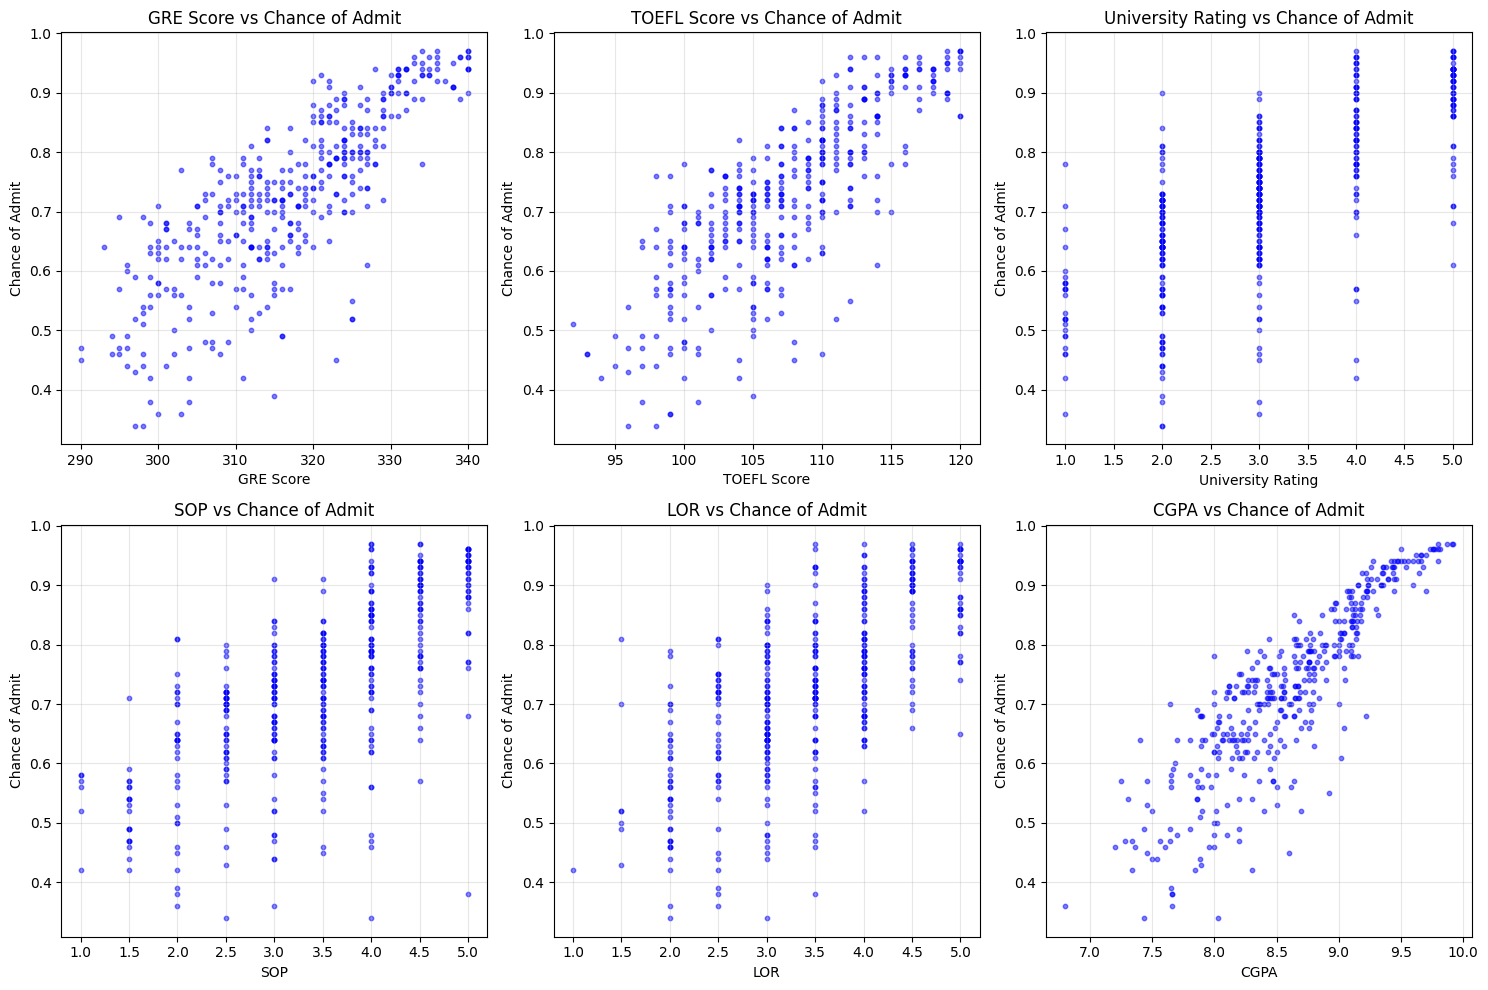

In [18]:
features = [1, 2, 3, 4, 5, 6]
target = 8

plt.figure(figsize=(15, 10))
for i, feature in enumerate(features):
    plt.subplot(2, 3, i + 1)
    plt.scatter(numList(admissionData, feature), numList(admissionData, target),
                alpha=0.5, s=10, color='blue')
    plt.title(f"{types[feature]} vs {types[target]}")
    plt.xlabel(types[feature])
    plt.ylabel(types[target])
    plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

По полученным диаграммам рассеивания можно сделать следующие выводы о шансах поступления в зависимости от конкретных величин:
- Шанс поступления напрямую зависим от результатов теста GRE, на диаграмме видна умеренная положительная связь;
- Аналогично, на шанс поступления напрямую влияют результат теста TOEFL; особенно сильная линейная связь есть между шансом поступления и средним баллом диплома бакалавра CGPA;
- Иные признаки также положительно влияют на шанс поступления, однако наблюдаемая связь слабая, не настолько заметная, как на остальных диаграммах.

#### Пункт 3. Построение моделей регрессии

Вспомогательная функция для построения полиномиальных признаков

In [19]:
def polynomicSample(data, degree):
    res = []
    for rec in data:
        for every in rec:
            x = float(every)
            for d in range(degree):
                res.append(x ** (d + 1))
    res = np.reshape(res, (len(data), -1))
    return res

Разделение выборки на тренировочную и проверочную, выделение целевых переменных:

In [20]:
admTr, admVal = train_test_split(admissionData, test_size=0.2, train_size=0.8)

y_tr = numList(admTr, 8)
y_val = numList(admVal, 8)

##### 3.1. Простая линейная регрессия

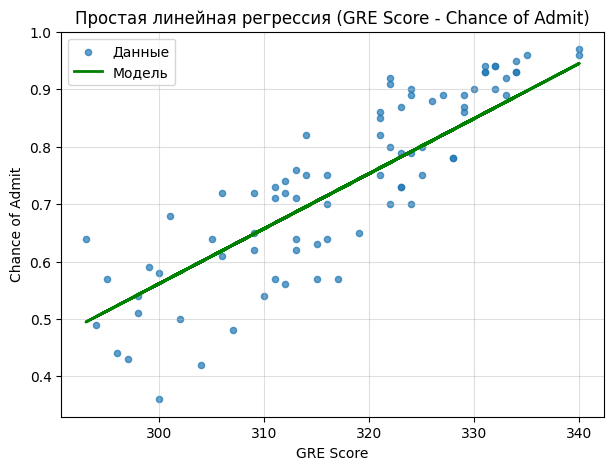

  Полученное уравнение: Y = 0.009585 * x + (-2.313974)
  R2  = 0.7419
  MSE = 0.006185
  RSS = 0.494799


In [21]:
X_tr = numList(admTr, 1).reshape(-1, 1)
X_val = numList(admVal, 1).reshape(-1, 1)

linR = LinearRegression().fit(X_tr, y_tr)
Y_pred = linR.predict(X_val)

r2 = r2_score(y_val, Y_pred)
mse = mean_squared_error(y_val, Y_pred)
rss = ((y_val - Y_pred) ** 2).sum()

plt.figure(figsize=(7, 5))
plt.scatter(X_val, y_val, alpha=0.7, s=20, label='Данные')
plt.plot(X_val, Y_pred, color='g', linewidth=2, label='Модель')
plt.title("Простая линейная регрессия (GRE Score - Chance of Admit)")
plt.xlabel("GRE Score")
plt.ylabel("Chance of Admit")
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

print(f"  Полученное уравнение: Y = {linR.coef_[0]:.6f} * x + ({linR.intercept_:.6f})")
print(f"  R2  = {r2:.4f}")
print(f"  MSE = {mse:.6f}")
print(f"  RSS = {rss:.6f}")

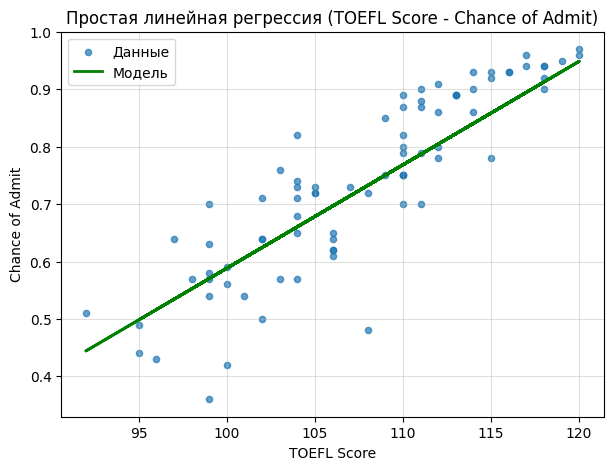

  Полученное уравнение: Y = 0.018026 * x + (-1.214197)
  R2  = 0.7593
  MSE = 0.005768
  RSS = 0.461473


In [22]:
X_tr = numList(admTr, 2).reshape(-1, 1)
X_val = numList(admVal, 2).reshape(-1, 1)

linR = LinearRegression().fit(X_tr, y_tr)
Y_pred = linR.predict(X_val)

r2 = r2_score(y_val, Y_pred)
mse = mean_squared_error(y_val, Y_pred)
rss = ((y_val - Y_pred) ** 2).sum()

plt.figure(figsize=(7, 5))
plt.scatter(X_val, y_val, alpha=0.7, s=20, label='Данные')
plt.plot(X_val, Y_pred, color='g', linewidth=2, label='Модель')
plt.title("Простая линейная регрессия (TOEFL Score - Chance of Admit)")
plt.xlabel("TOEFL Score")
plt.ylabel("Chance of Admit")
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

print(f"  Полученное уравнение: Y = {linR.coef_[0]:.6f} * x + ({linR.intercept_:.6f})")
print(f"  R2  = {r2:.4f}")
print(f"  MSE = {mse:.6f}")
print(f"  RSS = {rss:.6f}")

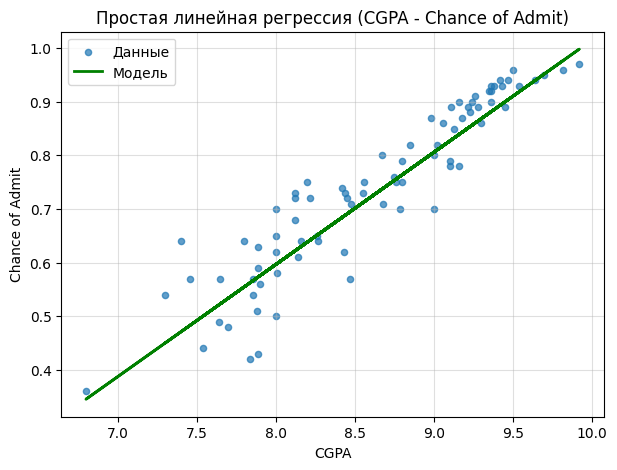

  Полученное уравнение: Y = 0.209135 * x + (-1.076751)
  R2  = 0.8567
  MSE = 0.003435
  RSS = 0.274770


In [23]:
X_tr = numList(admTr, 6).reshape(-1, 1)
X_val = numList(admVal, 6).reshape(-1, 1)

linR = LinearRegression().fit(X_tr, y_tr)
Y_pred = linR.predict(X_val)

r2 = r2_score(y_val, Y_pred)
mse = mean_squared_error(y_val, Y_pred)
rss = ((y_val - Y_pred) ** 2).sum()

plt.figure(figsize=(7, 5))
plt.scatter(X_val, y_val, alpha=0.7, s=20, label='Данные')
plt.plot(X_val, Y_pred, color='g', linewidth=2, label='Модель')
plt.title("Простая линейная регрессия (CGPA - Chance of Admit)")
plt.xlabel("CGPA")
plt.ylabel("Chance of Admit")
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

print(f"  Полученное уравнение: Y = {linR.coef_[0]:.6f} * x + ({linR.intercept_:.6f})")
print(f"  R2  = {r2:.4f}")
print(f"  MSE = {mse:.6f}")
print(f"  RSS = {rss:.6f}")

##### 3.2. Множественная линейная регрессия

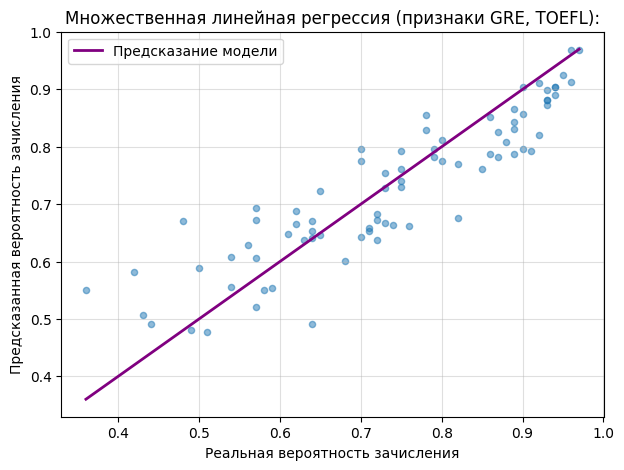

  Полученное уравнение: Y = -2.074070 + (0.005825) * X_GRE + (0.008857) * X_TOEFL
  R2  = 0.7978
  MSE = 0.004845
  RSS = 0.387600


In [24]:
feature_names = ["GRE", "TOEFL"]
X_tr = np.column_stack([numList(admTr, 1), numList(admTr, 2)])
X_val = np.column_stack([numList(admVal, 1), numList(admVal, 2)])

linR = LinearRegression().fit(X_tr, y_tr)
Y_pred = linR.predict(X_val)

r2 = r2_score(y_val, Y_pred)
mse = mean_squared_error(y_val, Y_pred)
rss = ((y_val - Y_pred) ** 2).sum()

plt.figure(figsize=(7, 5))
plt.scatter(y_val, Y_pred, alpha=0.5, s=20)
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()],
         color='purple', linewidth=2, label='Предсказание модели')
plt.title("Множественная линейная регрессия (признаки GRE, TOEFL):")
plt.xlabel("Реальная вероятность зачисления")
plt.ylabel("Предсказанная вероятность зачисления")
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

print(f"  Полученное уравнение: Y = {linR.intercept_:.6f}", end="")
for name, coef in zip(feature_names, linR.coef_):
    print(f" + ({coef:.6f}) * X_{name}", end="")
print()

print(f"  R2  = {r2:.4f}")
print(f"  MSE = {mse:.6f}")
print(f"  RSS = {rss:.6f}")

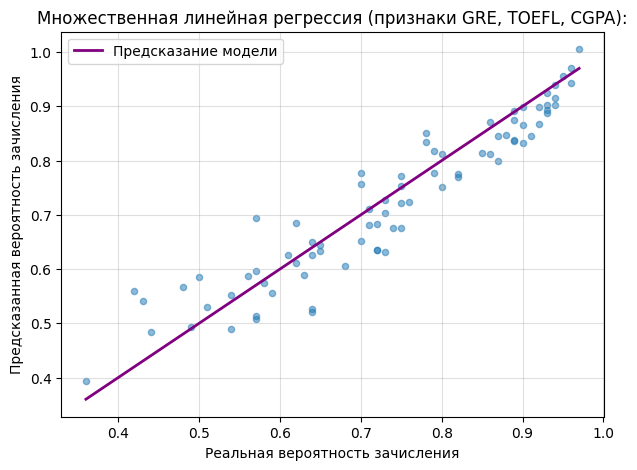

  Полученное уравнение: Y = -1.563791 + (0.002240) * X_GRE + (0.002746) * X_TOEFL + (0.148995) * X_CGPA
  R2  = 0.8848
  MSE = 0.002760
  RSS = 0.220807


In [25]:
feature_names = ["GRE", "TOEFL", "CGPA"]
X_tr = np.column_stack([numList(admTr, 1), numList(admTr, 2), numList(admTr, 6)])
X_val = np.column_stack([numList(admVal, 1), numList(admVal, 2), numList(admVal, 6)])

linR = LinearRegression().fit(X_tr, y_tr)
Y_pred = linR.predict(X_val)

r2 = r2_score(y_val, Y_pred)
mse = mean_squared_error(y_val, Y_pred)
rss = ((y_val - Y_pred) ** 2).sum()

plt.figure(figsize=(7, 5))
plt.scatter(y_val, Y_pred, alpha=0.5, s=20)
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()],
         color='purple', linewidth=2, label='Предсказание модели')
plt.title("Множественная линейная регрессия (признаки GRE, TOEFL, CGPA):")
plt.xlabel("Реальная вероятность зачисления")
plt.ylabel("Предсказанная вероятность зачисления")
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

print(f"  Полученное уравнение: Y = {linR.intercept_:.6f}", end="")
for name, coef in zip(feature_names, linR.coef_):
    print(f" + ({coef:.6f}) * X_{name}", end="")
print()

print(f"  R2  = {r2:.4f}")
print(f"  MSE = {mse:.6f}")
print(f"  RSS = {rss:.6f}")


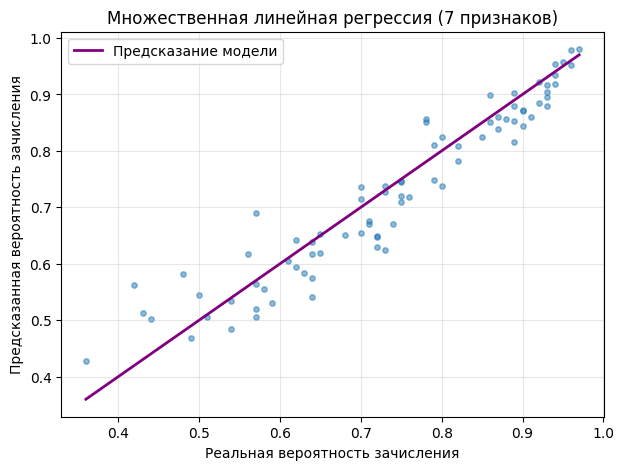

  Полученное уравнение: Y = -1.236414 + (0.001735) * X_(GRE) + (0.002752) * X_(TOEFL) + (0.005777) * X_(Univ Rating) + (0.000219) * X_(SOP) + (0.020799) * X_(LOR) + (0.117367) * X_(CGPA) + (0.024732) * X_(Research)
  R2  = 0.9015
  MSE = 0.002361
  RSS = 0.188912


In [26]:
feature_names = ["GRE", "TOEFL", "Univ Rating", "SOP", "LOR", "CGPA", "Research"]
X_tr = np.column_stack([numList(admTr, f) for f in range(1, 8)])
X_val = np.column_stack([numList(admVal, f) for f in range(1, 8)])

linR = LinearRegression().fit(X_tr, y_tr)
Y_pred = linR.predict(X_val)

r2 = r2_score(y_val, Y_pred)
mse = mean_squared_error(y_val, Y_pred)
rss = ((y_val - Y_pred) ** 2).sum()

plt.figure(figsize=(7, 5))
plt.scatter(y_val, Y_pred, alpha=0.5, s=15)
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()],
         color='purple', linewidth=2, label='Предсказание модели')
plt.title("Множественная линейная регрессия (7 признаков)")
plt.xlabel("Реальная вероятность зачисления")
plt.ylabel("Предсказанная вероятность зачисления")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"  Полученное уравнение: Y = {linR.intercept_:.6f}", end="")
for name, coef in zip(feature_names, linR.coef_):
    print(f" + ({coef:.6f}) * X_({name})", end="")
print()

print(f"  R2  = {r2:.4f}")
print(f"  MSE = {mse:.6f}")
print(f"  RSS = {rss:.6f}")

##### 3.3. Полиномиальная по независимым переменным регрессия

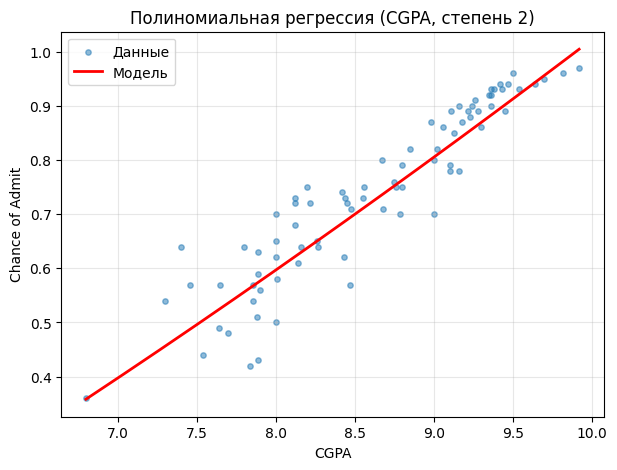

  Уравнение: Y = -0.747445 + (0.132164) * CGPA^1 + (0.004478) * CGPA^2
  R2  = 0.8581
  MSE = 0.003401
  RSS = 0.272105


In [32]:
feature_names = ["CGPA^1", "CGPA^2"]
X_tr = polynomicSample(numList(admTr, 6).reshape(-1, 1), 2)
X_val = polynomicSample(numList(admVal, 6).reshape(-1, 1), 2)

linR = LinearRegression().fit(X_tr, y_tr)
Y_pred = linR.predict(X_val)

r2 = r2_score(y_val, Y_pred)
mse = mean_squared_error(y_val, Y_pred)
rss = ((y_val - Y_pred) ** 2).sum()

X_plot = np.linspace(numList(admVal, 6).min(), numList(admVal, 6).max(), 200).reshape(-1, 1)
X_plot_poly = polynomicSample(X_plot, 2)
Y_plot = linR.predict(X_plot_poly)

plt.figure(figsize=(7, 5))
plt.scatter(numList(admVal, 6), y_val, alpha=0.5, s=15, label='Данные')
plt.plot(X_plot, Y_plot, color='r', linewidth=2, label='Модель')
plt.title("Полиномиальная регрессия (CGPA, степень 2)")
plt.xlabel("CGPA")
plt.ylabel("Chance of Admit")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"  Уравнение: Y = {linR.intercept_:.6f}", end="")
for name, coef in zip(feature_names, linR.coef_):
    print(f" + ({coef:.6f}) * {name}", end="")
print()
print(f"  R2  = {r2:.4f}")
print(f"  MSE = {mse:.6f}")
print(f"  RSS = {rss:.6f}")

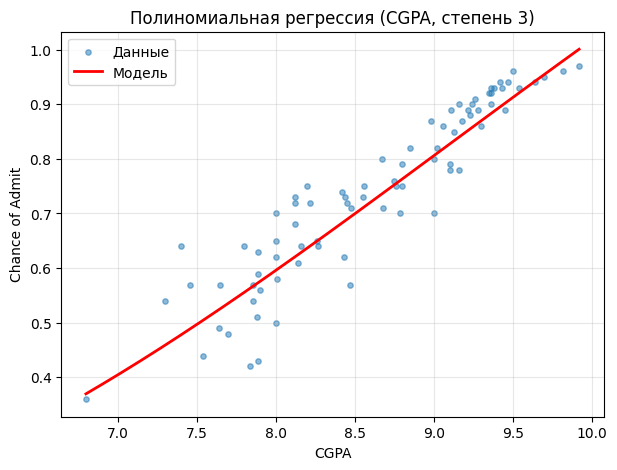

  Уравнение: Y = 1.010387 + (-0.487627) * CGPA^1 + (0.077036) * CGPA^2 + (-0.002820) * CGPA^3
  R2  = 0.8589
  MSE = 0.003382
  RSS = 0.270540


In [33]:
feature_names = ["CGPA^1", "CGPA^2", "CGPA^3"]
X_tr = polynomicSample(numList(admTr, 6).reshape(-1, 1), 3)
X_val = polynomicSample(numList(admVal, 6).reshape(-1, 1), 3)

linR = LinearRegression().fit(X_tr, y_tr)
Y_pred = linR.predict(X_val)

r2 = r2_score(y_val, Y_pred)
mse = mean_squared_error(y_val, Y_pred)
rss = ((y_val - Y_pred) ** 2).sum()

X_plot = np.linspace(numList(admVal, 6).min(), numList(admVal, 6).max(), 200).reshape(-1, 1)
X_plot_poly = polynomicSample(X_plot, 3)
Y_plot = linR.predict(X_plot_poly)

plt.figure(figsize=(7, 5))
plt.scatter(numList(admVal, 6), y_val, alpha=0.5, s=15, label='Данные')
plt.plot(X_plot, Y_plot, color='r', linewidth=2, label='Модель')
plt.title("Полиномиальная регрессия (CGPA, степень 3)")
plt.xlabel("CGPA")
plt.ylabel("Chance of Admit")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"  Уравнение: Y = {linR.intercept_:.6f}", end="")
for name, coef in zip(feature_names, linR.coef_):
    print(f" + ({coef:.6f}) * {name}", end="")
print()
print(f"  R2  = {r2:.4f}")
print(f"  MSE = {mse:.6f}")
print(f"  RSS = {rss:.6f}")

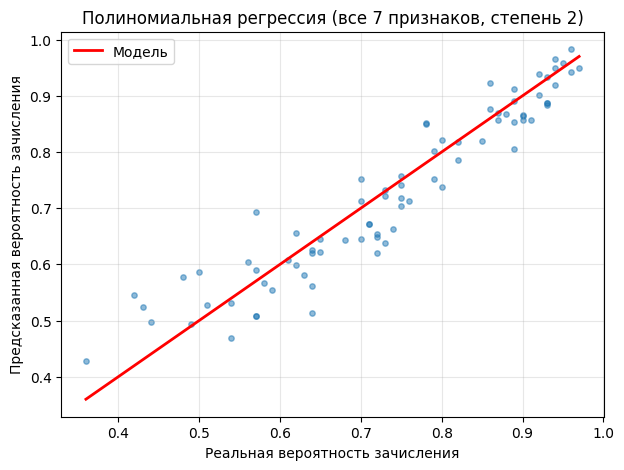

  Свободный член (beta_0): -3.193137
  Коэффициенты:
    GRE^1          : 0.007431
    GRE^2          : -0.000009
    TOEFL^1        : 0.007946
    TOEFL^2        : -0.000023
    Univ Rating^1  : -0.042585
    Univ Rating^2  : 0.007508
    SOP^1          : 0.017136
    SOP^2          : -0.002398
    LOR^1          : -0.021369
    LOR^2          : 0.006129
    CGPA^1         : 0.324508
    CGPA^2         : -0.012115
    Research^1     : 0.012726
    Research^2     : 0.012726
  R2  = 0.8921
  MSE = 0.002586
  RSS = 0.206888


In [35]:
base_names = ["GRE", "TOEFL", "Univ Rating", "SOP", "LOR", "CGPA", "Research"]
feature_names = [f"{n}^{d}" for n in base_names for d in [1, 2]]

X_tr_raw = np.column_stack([numList(admTr, f) for f in range(1, 8)])
X_val_raw = np.column_stack([numList(admVal, f) for f in range(1, 8)])

X_tr = polynomicSample(X_tr_raw, 2)
X_val = polynomicSample(X_val_raw, 2)

linR = LinearRegression().fit(X_tr, y_tr)
Y_pred = linR.predict(X_val)

r2 = r2_score(y_val, Y_pred)
mse = mean_squared_error(y_val, Y_pred)
rss = ((y_val - Y_pred) ** 2).sum()

plt.figure(figsize=(7, 5))
plt.scatter(y_val, Y_pred, alpha=0.5, s=15)
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()],
         color='r', linewidth=2, label='Модель')
plt.title("Полиномиальная регрессия (все 7 признаков, степень 2)")
plt.xlabel("Реальная вероятность зачисления")
plt.ylabel("Предсказанная вероятность зачисления")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"  Свободный член (beta_0): {linR.intercept_:.6f}")
print("  Коэффициенты:")
for name, coef in zip(feature_names, linR.coef_):
    print(f"    {name:<15}: {coef:.6f}")
print(f"  R2  = {r2:.4f}")
print(f"  MSE = {mse:.6f}")
print(f"  RSS = {rss:.6f}")
